In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import KFold,cross_val_score, StratifiedKFold
from sklearn.compose import make_column_selector, make_column_transformer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.preprocessing import StandardScaler, MaxAbsScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, log_loss

In [5]:
df = pd.read_csv("Vehicle (2).csv")
df

,Comp,Circ,D.Circ,Rad.Ra,Pr.Axis.Ra,Max.L.Ra,Scat.Ra,Elong,Pr.Axis.Rect,Max.L.Rect,Sc.Var.Maxis,Sc.Var.maxis,Ra.Gyr,Skew.Maxis,Skew.maxis,Kurt.maxis,Kurt.Maxis,Holl.Ra,Class
0,95,48,83,178,72,10,162,42,20,159,176,379,184,70,6,16,187,197,van
1,91,41,84,141,57,9,149,45,19,143,170,330,158,72,9,14,189,199,van
2,104,50,106,209,66,10,207,32,23,158,223,635,220,73,14,9,188,196,saab
3,93,41,82,159,63,9,144,46,19,143,160,309,127,63,6,10,199,207,van
4,85,44,70,205,103,52,149,45,19,144,241,325,188,127,9,11,180,183,bus
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
841,93,39,87,183,64,8,169,40,20,134,200,422,149,72,7,25,188,195,saab
842,89,46,84,163,66,11,159,43,20,159,173,368,176,72,1,20,186,197,van
843,106,54,101,222,67,12,222,30,25,173,228,721,200,70,3,4,187,201,saab
844,86,36,78,146,58,7,135,50,18,124,155,270,148,66,0,25,190,195,saab


In [46]:
X, y = df.drop("Class",axis=1), df["Class"]
le = LabelEncoder()
y_le = le.fit_transform(y)

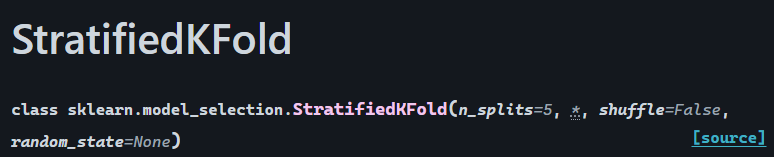

In [8]:
gbm = GradientBoostingClassifier(random_state=26)
kfold = StratifiedKFold(n_splits=5,shuffle=True,random_state=26)
res = cross_val_score(gbm, X, y, cv=kfold)  #scoring="f1_micro"
res

array([0.77058824, 0.76923077, 0.78698225, 0.78106509, 0.75147929])

In [11]:
res = cross_val_score(gbm, X, y, cv=kfold,scoring="f1_micro")
res

array([0.77058824, 0.76923077, 0.78698225, 0.78106509, 0.75147929])

In [12]:
res = cross_val_score(gbm, X, y, cv=kfold,scoring="f1_macro")
res

array([0.7686946 , 0.76220273, 0.78574501, 0.77873208, 0.74881044])

In [13]:
res = cross_val_score(gbm, X, y, cv=kfold,scoring="neg_log_loss")
res

array([-0.46420906, -0.47148921, -0.43516682, -0.47498426, -0.55013841])

In [52]:
lr = np.linspace(0.01,0.9,10)
max_depth = [None, 2, 3, 4]
n_estimators = [25, 50, 100]
scores = []
for l in tqdm(lr):
    for m in max_depth:
        for n in n_estimators:
            gdc = GradientBoostingClassifier(random_state=26,learning_rate=l, n_estimators= n, max_depth= m)
            kfold = StratifiedKFold(n_splits=5,shuffle=True,random_state=26)
            res = cross_val_score(gbm, X, y, cv=kfold,scoring="neg_log_loss")  #scoring="accuracy"
            scores.append([l,m,n,np.mean(res)])
df_scores = pd.DataFrame(scores, columns=["Learning Rate","Max Depth", "N", "log_loss"])
df_scores.sort_values("log_loss",ascending=False)

100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [12:37<00:00, 75.78s/it]


,Learning Rate,Max Depth,N,log_loss
0,0.01,NaN,25,-0.479198
1,0.01,NaN,50,-0.479198
2,0.01,NaN,100,-0.479198
3,0.01,2.0,25,-0.479198
4,0.01,2.0,50,-0.479198
...,...,...,...,...
115,0.90,3.0,50,-0.479198
116,0.90,3.0,100,-0.479198
117,0.90,4.0,25,-0.479198
118,0.90,4.0,50,-0.479198


,Learning Rate,Max Depth,N,Accuracy
0,0.01,NaN,25,-0.479198
1,0.01,NaN,50,-0.479198
2,0.01,NaN,100,-0.479198
3,0.01,2.0,25,-0.479198
4,0.01,2.0,50,-0.479198
...,...,...,...,...
115,0.90,3.0,50,-0.479198
116,0.90,3.0,100,-0.479198
117,0.90,4.0,25,-0.479198
118,0.90,4.0,50,-0.479198


In [36]:
import warnings
from sklearn.exceptions import ConvergenceWarning

# Suppress convergence and other runtime warnings
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UserWarning)

In [48]:
solvers = ["lbfgs","newton-cg","newton-cholesky"]
scores = []
for s in tqdm(solvers):
    for c in Cs:
            lr = LogisticRegression(solver=s)
            kfold = StratifiedKFold(n_splits=5,shuffle=True,random_state=26)
            res1 = cross_val_score(lr, X, y, cv=kfold, scoring="neg_log_loss" )  #scoring="accuracy"
            res2 = cross_val_score(lr, X, y, cv=kfold)  #scoring="accuracy"
            scores.append([s,np.mean(res1),np.mean(res2)])
df_scores = pd.DataFrame(scores, columns=["Solver","Loss","Accuracy"])

100%|████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:52<00:00, 17.41s/it]


In [49]:
df_scores.sort_values("Accuracy",ascending=False)

,Solver,Loss,Accuracy
6,newton-cg,-0.416957,0.810860
5,newton-cg,-0.416957,0.810860
7,newton-cg,-0.416957,0.810860
8,newton-cg,-0.416957,0.810860
9,newton-cg,-0.416957,0.810860
10,newton-cholesky,-0.438304,0.808493
11,newton-cholesky,-0.438304,0.808493
13,newton-cholesky,-0.438304,0.808493
12,newton-cholesky,-0.438304,0.808493
14,newton-cholesky,-0.438304,0.808493


In [42]:
solvers = ["lbfgs","newton-cg","newton-cholesky"]
Cs = np.linspace(0.01,3,5)
scores = []
for s in tqdm(solvers):
    for c in Cs:
            lr = LogisticRegression(solver=s, C=c)
            kfold = StratifiedKFold(n_splits=5,shuffle=True,random_state=26)
            res1 = cross_val_score(lr, X, y, cv=kfold, scoring="neg_log_loss" )  #scoring="accuracy"
            res2 = cross_val_score(lr, X, y, cv=kfold)  #scoring="accuracy"
            scores.append([s,c,np.mean(res1),np.mean(res2)])
df_scores = pd.DataFrame(scores, columns=["Solver","C","log_loss","Accuracy"])

100%|████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:44<00:00, 14.92s/it]


In [43]:
df_scores.sort_values("Accuracy",ascending=False)

,Solver,C,log_loss,Accuracy
7,newton-cg,1.5050,-0.421581,0.812043
8,newton-cg,2.2525,-0.427825,0.812036
6,newton-cg,0.7575,-0.414607,0.809676
9,newton-cg,3.0000,-0.431223,0.809676
11,newton-cholesky,0.7575,-0.432451,0.808493
12,newton-cholesky,1.5050,-0.447914,0.807316
13,newton-cholesky,2.2525,-0.458194,0.807309
14,newton-cholesky,3.0000,-0.465749,0.806126
5,newton-cg,0.0100,-0.472532,0.786029
10,newton-cholesky,0.0100,-0.470541,0.786022


# Gridsearch CV

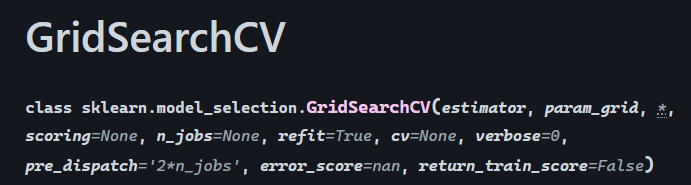

In [44]:
from sklearn.model_selection import GridSearchCV

In [47]:
params = {"solver" : ["lbfgs","newton-cg","newton-cholesky"],
          "C" : np.linspace(0.01,3,5)}
lr = LogisticRegression()
gcv = GridSearchCV(lr, param_grid=params,cv=kfold,scoring="neg_log_loss")
gcv.fit(X,y_le)
print("Best params : ", gcv.best_params_)
print("Best score : ", gcv.best_score_)

Best params :  {'C': np.float64(0.7575000000000001), 'solver': 'newton-cg'}
Best score :  -0.41460687009627517
